# Python Exercises - Pandas

## Problem 1


Imagine three people, e.g. family, friends, cohort.

Create a pandas data frame called `cities_df` that contains the following columns:

* Cities - At least 5 cities in the US
* States - The states that those cities reside in
* Region - The region that those cities reside in (NW, SW, Midwest, etc.)
* Times_1 - The number of times person 1 has been to each city
* Times_2 - The number of times person 2 has been to each city
* Times_3 - The number of times person 3 has been to each city


In [1]:
import pandas as pd


In [2]:
# Solution
cities_df = pd.DataFrame(
    {'Cities': ['Albuquerque', "Denver", 'Tucson', 'LA', 'Dallas'],
     'States': ['NM', 'CO', 'AZ', 'CA', 'TX'],
     'Region': ['SW', 'SW', 'SW', 'W', "Midwest"],
     'Times_1': [2,4,1,1,1],
     'Times_2': [0,1,3,0,1],
     'Times_3': [2,2,5,1,0],
     }
)
cities_df

,Cities,States,Region,Times_1,Times_2,Times_3
0,Albuquerque,NM,SW,2,0,2
1,Denver,CO,SW,4,1,2
2,Tucson,AZ,SW,1,3,5
3,LA,CA,W,1,0,1
4,Dallas,TX,Midwest,1,1,0


In [3]:
# Solution - variant
cities_df = pd.DataFrame()
cities_df['Cities']  = ['Albuquerque', "Denver", 'Tucson', 'LA', 'Dallas']
cities_df['States']  = ['NM', 'CO', 'AZ', 'CA', 'TX']
cities_df['Region']  = ['SW', 'SW', 'SW', 'W', "Midwest"]
cities_df['Times_1'] = [2,4,1,1,1]
cities_df['Times_2'] = [0,1,3,0,1]
cities_df['Times_3'] = [2,2,5,1,0]

cities_df

,Cities,States,Region,Times_1,Times_2,Times_3
0,Albuquerque,NM,SW,2,0,2
1,Denver,CO,SW,4,1,2
2,Tucson,AZ,SW,1,3,5
3,LA,CA,W,1,0,1
4,Dallas,TX,Midwest,1,1,0


## Problem 2


Use the `.describe()` and `.info()` methods on your data frame


In [4]:
cities_df.shape

(5, 6)

In [5]:
cities_df.describe( include = "all" ).transpose()

,count,unique,top,freq,mean,std,min,25%,50%,75%,max
Cities,5,5,Albuquerque,1,NaN,NaN,NaN,NaN,NaN,NaN,NaN
States,5,5,NM,1,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Region,5,3,SW,3,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Times_1,5.0,NaN,NaN,NaN,1.8,1.30384,1.0,1.0,1.0,2.0,4.0
Times_2,5.0,NaN,NaN,NaN,1.0,1.224745,0.0,0.0,1.0,1.0,3.0
Times_3,5.0,NaN,NaN,NaN,2.0,1.870829,0.0,1.0,2.0,2.0,5.0


In [6]:
cities_df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 5 entries, 0 to 4
Data columns (total 6 columns):
 #   Column   Non-Null Count  Dtype 
---  ------   --------------  ----- 
 0   Cities   5 non-null      object
 1   States   5 non-null      object
 2   Region   5 non-null      object
 3   Times_1  5 non-null      int64 
 4   Times_2  5 non-null      int64 
 5   Times_3  5 non-null      int64 
dtypes: int64(3), object(3)
memory usage: 372.0+ bytes


## Problem 3


Use indexing to access the Cities column

In [7]:
cities_df['Cities']

,Cities
0,Albuquerque
1,Denver
2,Tucson
3,LA
4,Dallas


In [8]:
cities_df.loc[:, 'Cities']

,Cities
0,Albuquerque
1,Denver
2,Tucson
3,LA
4,Dallas


In [9]:
cities_df.iloc[:, 0]

,Cities
0,Albuquerque
1,Denver
2,Tucson
3,LA
4,Dallas


In [10]:
idx = list(cities_df.columns).index("Cities")
cities_df.iloc[:, idx]

,Cities
0,Albuquerque
1,Denver
2,Tucson
3,LA
4,Dallas


In [11]:
idx = cities_df.columns.get_loc("Cities")
cities_df.iloc[:, idx]

,Cities
0,Albuquerque
1,Denver
2,Tucson
3,LA
4,Dallas


## Problem 4


Create a new column called `Total_Times` that contains the total number of times all team members have been to each city.

In [12]:
# Solution
cities_df['Total_Times'] = cities_df['Times_1'] + cities_df['Times_2'] + cities_df['Times_3']
cities_df

,Cities,States,Region,Times_1,Times_2,Times_3,Total_Times
0,Albuquerque,NM,SW,2,0,2,4
1,Denver,CO,SW,4,1,2,7
2,Tucson,AZ,SW,1,3,5,9
3,LA,CA,W,1,0,1,2
4,Dallas,TX,Midwest,1,1,0,2


In [13]:
# Solution - variant
cities_df['Total_Times'] = cities_df[['Times_1','Times_2','Times_3']].sum(axis=1)
cities_df

,Cities,States,Region,Times_1,Times_2,Times_3,Total_Times
0,Albuquerque,NM,SW,2,0,2,4
1,Denver,CO,SW,4,1,2,7
2,Tucson,AZ,SW,1,3,5,9
3,LA,CA,W,1,0,1,2
4,Dallas,TX,Midwest,1,1,0,2


In [14]:
# Solution - variant
cols = [ c for c in cities_df.columns if c.startswith("Times") ]
cities_df['Total_Times'] = cities_df[cols].sum(axis=1)
cities_df

,Cities,States,Region,Times_1,Times_2,Times_3,Total_Times
0,Albuquerque,NM,SW,2,0,2,4
1,Denver,CO,SW,4,1,2,7
2,Tucson,AZ,SW,1,3,5,9
3,LA,CA,W,1,0,1,2
4,Dallas,TX,Midwest,1,1,0,2


In [15]:
# Solution - variant
cols = cities_df.columns.str.startswith("Times")
cities_df['Total_Times'] = cities_df.loc[:, cols].sum(axis=1)
cities_df

,Cities,States,Region,Times_1,Times_2,Times_3,Total_Times
0,Albuquerque,NM,SW,2,0,2,4
1,Denver,CO,SW,4,1,2,7
2,Tucson,AZ,SW,1,3,5,9
3,LA,CA,W,1,0,1,2
4,Dallas,TX,Midwest,1,1,0,2


In [16]:
# Solution - variant
cols = cities_df.columns.str.startswith("Times")
cities_df['Total_Times'] = cities_df.iloc[:, cols].sum(axis=1)
cities_df

,Cities,States,Region,Times_1,Times_2,Times_3,Total_Times
0,Albuquerque,NM,SW,2,0,2,4
1,Denver,CO,SW,4,1,2,7
2,Tucson,AZ,SW,1,3,5,9
3,LA,CA,W,1,0,1,2
4,Dallas,TX,Midwest,1,1,0,2


## Problem 5


Use indexing to access the cities that have been travelled to more than two times.

In [17]:
filter = ( cities_df[ 'Total_Times'] > 2 )
cities_df[ filter ]

,Cities,States,Region,Times_1,Times_2,Times_3,Total_Times
0,Albuquerque,NM,SW,2,0,2,4
1,Denver,CO,SW,4,1,2,7
2,Tucson,AZ,SW,1,3,5,9


## Problem 6


Make a bar plot with `Cities` on the x axis and `Total_Times` on the y axis.

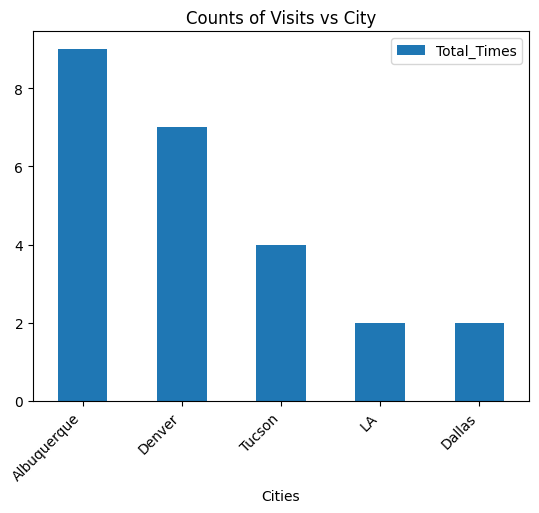

In [18]:
# uses method chaining across multiple lines; note the wrapping parentheses
plot = (
  cities_df
  .sort_values('Total_Times', ascending = False )
  .plot(
    kind = 'bar',
    x = 'Cities',
    y = 'Total_Times',
    title = 'Counts of Visits vs City',
  )
)
plot.set_xticklabels(
  cities_df["Cities"],
  rotation = 45,
  ha = "right",
) ;


## Problem 7


Drop the 'Total_Times' column from your data frame.

In [19]:
cities_df.drop(
  columns = ['Total_Times'],
  inplace = True,
)
cities_df

,Cities,States,Region,Times_1,Times_2,Times_3
0,Albuquerque,NM,SW,2,0,2
1,Denver,CO,SW,4,1,2
2,Tucson,AZ,SW,1,3,5
3,LA,CA,W,1,0,1
4,Dallas,TX,Midwest,1,1,0


## Problem 8


Restructure your data frame using the pandas `.melt()` method. In the `.melt()` method, specify `id_vars = ['Cities', 'States', 'Region']`. Save the melted data frame as a new variable called `cities_df_melted`. Print out `cities_df_melted`.

> Note: make sure to read through the documentation for the `.melt()` method to understand what the method does.

In [20]:
cities_df.melt?

In [21]:
cities_df.sort_values("Cities")

,Cities,States,Region,Times_1,Times_2,Times_3
0,Albuquerque,NM,SW,2,0,2
4,Dallas,TX,Midwest,1,1,0
1,Denver,CO,SW,4,1,2
3,LA,CA,W,1,0,1
2,Tucson,AZ,SW,1,3,5


In [22]:
cities_df_melted = cities_df.melt(id_vars = ['Cities', 'States', 'Region'])
cities_df_melted.sort_values(["Cities", "variable"])

,Cities,States,Region,variable,value
0,Albuquerque,NM,SW,Times_1,2
5,Albuquerque,NM,SW,Times_2,0
10,Albuquerque,NM,SW,Times_3,2
4,Dallas,TX,Midwest,Times_1,1
9,Dallas,TX,Midwest,Times_2,1
14,Dallas,TX,Midwest,Times_3,0
1,Denver,CO,SW,Times_1,4
6,Denver,CO,SW,Times_2,1
11,Denver,CO,SW,Times_3,2
3,LA,CA,W,Times_1,1


## Problem 9


Use the seaborn `barplot()` function to create a barplot of `cities_df_melted` with `Cities` on the x axis, `value` on the y axis and the hue parameter set to `variable`.

In [23]:
import seaborn as sns
sns.barplot?


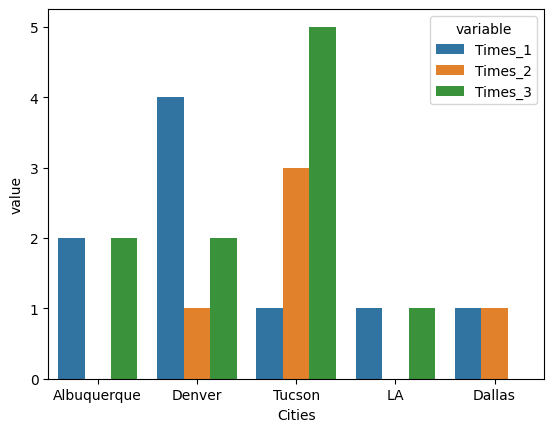

In [24]:
sns.barplot(
    x = cities_df_melted['Cities'],
    y = cities_df_melted['value'],
    hue = cities_df_melted['variable'],
    ) ;